# A toy model with epistemic uncertainties, step 1: the input files

A synthetic static slip inversion whose Green's functions are wrong, and how AlTar accounts for it with the prediction covariance $\mathbf{C}_\mathrm{p}$ (Duputel et al., 2014). This step makes the data and the input files; [step 2](toymodel_step2.ipynb) runs the inversions.

The fault is a 2.5-dimensional strike-slip fault: vertical, infinitely long along strike, and breaking the surface. The $\mathbf{x}_1$ axis is perpendicular to the fault, $\mathbf{x}_2$ is vertical and $\mathbf{x}_3$ is along strike, and the free surface is the $(\mathbf{x}_1, \mathbf{x}_3)$ plane (Figure 1). The fault slips along strike, so the surface moves along $\mathbf{x}_3$ only, by an amount that depends on the distance $x_1$ from the fault.

![Figure 1.](intro_cp_fig.png)

The fault bounds two media of different shear moduli. The synthetic data come from that heterogeneous medium, but the inversions use the Green's functions of a homogeneous half space: an error in the forward model, an epistemic uncertainty, which $\mathbf{C}_\mathrm{p}$ describes. This notebook

1. sets up the toy model;
2. computes the data and their covariance $\mathbf{C}_\mathrm{d}$;
3. computes the Green's functions, for the heterogeneous medium and for a homogeneous half space;
4. computes $\mathbf{C}_\mathrm{p}$, from the sensitivity of the Green's functions to the shear moduli;
5. writes the input files for AlTar.

See the chapter [Model Uncertainty](https://altar2.readthedocs.io/en/latest/guide/StaticCp.html) of the AlTar guide for the theory.

## 1. The toy model

In [1]:
import os
import numpy as np
import matplotlib.pyplot as plt
import h5py

# the directory for the input files of AlTar
name = 'test1'

The fault reaches 10 km deep, and is cut down dip into 20 patches, 500 m each. It is long enough along strike, 500 km, to be infinite for the stations; only the area of the patches depends on it.

In [2]:
length = 500e3  # the length of the fault along strike, in m
width = 10e3    # its width down dip, in m: the depth it reaches
patches = 20    # the patches down dip, 500 m each

The shear moduli on either side of the fault; only their ratio matters here. The fault slips 10 m along strike, uniformly, from the surface to its bottom.

In [3]:
mu1 = 2.0  # the shear modulus on the West side of the fault, x1 < 0
mu2 = 5.0  # and on the East side, x1 > 0
s = 10.0   # the slip, in m

## 2. The data and their covariance

### 2.1 The data

The stations are on a line across the fault, 70 on the West side and 30 on the East side: a network that covers one side of the fault better than the other. With a symmetric network, the epistemic uncertainties of this toy model would only change the fit to the data, not the inferred slip.

In [4]:
x = np.concatenate((np.linspace(-40e3, -500, 70), np.linspace(500, 15e3, 30)))

The surface displacement of an infinitely long vertical strike-slip fault between two media of shear moduli $\mu_1$ and $\mu_2$, slipping by $s$ from the surface down to depth $d$ (Segall, 2010), is, on each side:

$$
u^{(1)}(x_1, x_2 = 0) = \frac{2 s}{\pi} \, \frac{\mu_2}{\mu_1 + \mu_2} \, \tan^{-1} \left( \frac{d}{x_1} \right), \qquad
u^{(2)}(x_1, x_2 = 0) = \frac{2 s}{\pi} \, \frac{\mu_1}{\mu_1 + \mu_2} \, \tan^{-1} \left( \frac{d}{x_1} \right)
$$

The compliant side moves more than the stiff one. With $\mu_1 = \mu_2$, both reduce to the displacement in a homogeneous half space, $\frac{s}{\pi} \tan^{-1}(d / x_1)$.

In [5]:
def displacement(x, s, d, mu1, mu2):
    # the side with mu1 (x < 0) moves with mu2 / (mu1 + mu2), the side with mu2 with mu1 / (mu1 + mu2)
    share = np.where(x < 0, mu2, mu1) / (mu1 + mu2)
    return 2 * s / np.pi * share * np.arctan(d / x)

u_x3 = displacement(x, s, width, mu1, mu2)

The data have no noise: their only misfit to the predictions of the inversions is the error of the Green's functions. AlTar expects three components at each station, East ($\mathbf{x}_1$), North ($\mathbf{x}_3$, along strike) and Up ($\mathbf{x}_2$); the other two are zero here.

In [6]:
u = np.concatenate((np.zeros_like(u_x3), u_x3, np.zeros_like(u_x3)))
print(f"{len(u)} observations; the largest displacement {np.abs(u_x3).max():.2f} m")

300 observations; the largest displacement 6.92 m


### 2.2 The data covariance $\mathbf{C}_\mathrm{d}$

Independent data, with a standard deviation of 2% of the largest displacement:

In [7]:
sigma_d = 0.02 * np.abs(u_x3).max()
Cd = np.diag(np.full(len(u), sigma_d ** 2))
print(f"data standard deviation {100 * sigma_d:.1f} cm")

data standard deviation 13.8 cm


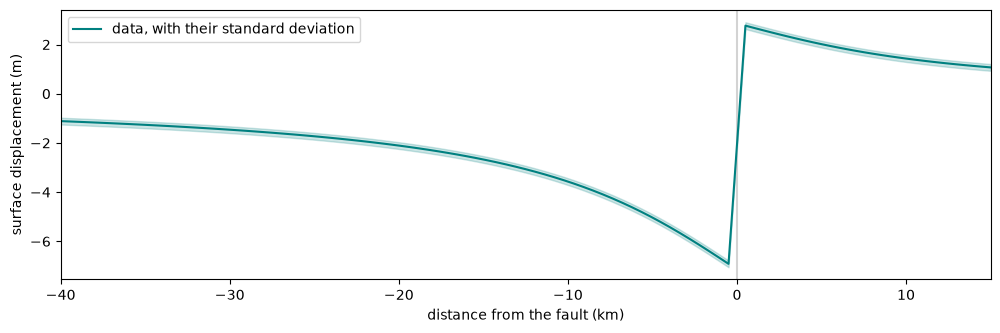

In [8]:
fig, ax = plt.subplots(figsize=(12, 3.5))
ax.axvline(0, color='lightgray')
ax.fill_between(x / 1e3, u_x3 - sigma_d, u_x3 + sigma_d, color='teal', alpha=0.2)
ax.plot(x / 1e3, u_x3, color='teal', label='data, with their standard deviation')
ax.set_xlim(-40, 15)
ax.set_xlabel('distance from the fault (km)'); ax.set_ylabel('surface displacement (m)')
ax.legend()
plt.show()

## 3. The Green's functions

The Green's functions are the surface displacements for a unit slip on each patch. A patch between depths $d_i$ and $d_{i+1}$ is the difference of two dislocations from the surface, down to $d_{i+1}$ and down to $d_i$:

$$
\mathbf{G}(x_j, f_i) = \frac{2}{\pi} \, \frac{\mu}{\mu_1 + \mu_2} \left[ \tan^{-1} \left( \frac{d_{i+1}}{x_j} \right) - \tan^{-1} \left( \frac{d_i}{x_j} \right) \right]
$$

with $\mu = \mu_2$ on the West side, $x_j < 0$, and $\mu = \mu_1$ on the East side. The Green's functions of a homogeneous half space are those with $\mu_1 = \mu_2$.

In [9]:
def greens(x, width, patches, mu1, mu2):
    # (stations, patches): the displacement along strike for a unit slip on each patch
    d = np.linspace(0, width, patches + 1)
    share = np.where(x < 0, mu2, mu1) / (mu1 + mu2)
    return 2 / np.pi * share[:, None] * (np.arctan(d[None, 1:] / x[:, None]) - np.arctan(d[None, :-1] / x[:, None]))

G_het = greens(x, width, patches, mu1, mu2)    # the medium of the data
G_hom = greens(x, width, patches, 1.0, 1.0)    # the homogeneous half space of the inversions

For the shallowest and the deepest patches:

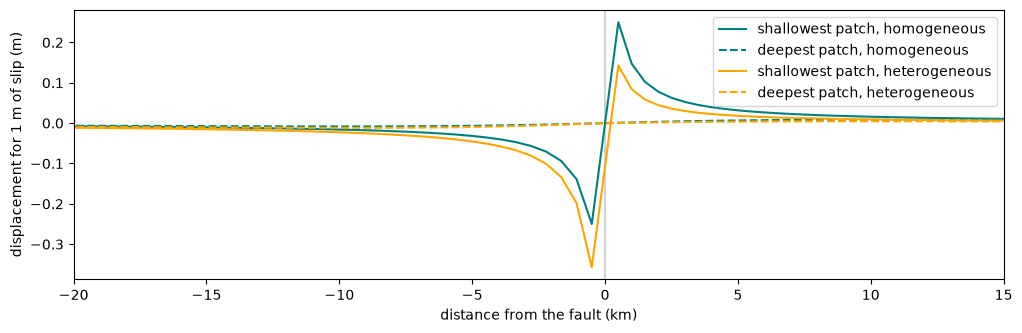

In [10]:
fig, ax = plt.subplots(figsize=(12, 3.5))
ax.axvline(0, color='lightgray')
for G, color, medium in [(G_hom, 'teal', 'homogeneous'), (G_het, 'orange', 'heterogeneous')]:
    ax.plot(x / 1e3, G[:, 0], color=color, label=f'shallowest patch, {medium}')
    ax.plot(x / 1e3, G[:, -1], '--', color=color, label=f'deepest patch, {medium}')
ax.set_xlim(-20, 15)
ax.set_xlabel('distance from the fault (km)'); ax.set_ylabel('displacement for 1 m of slip (m)')
ax.legend()
plt.show()

The heterogeneous Green's functions are larger on the compliant West side and smaller on the stiff East side. How they change with the ratio of the shear moduli, for $\mu_1$ from 1 to 8 and $\mu_2 = 5$:

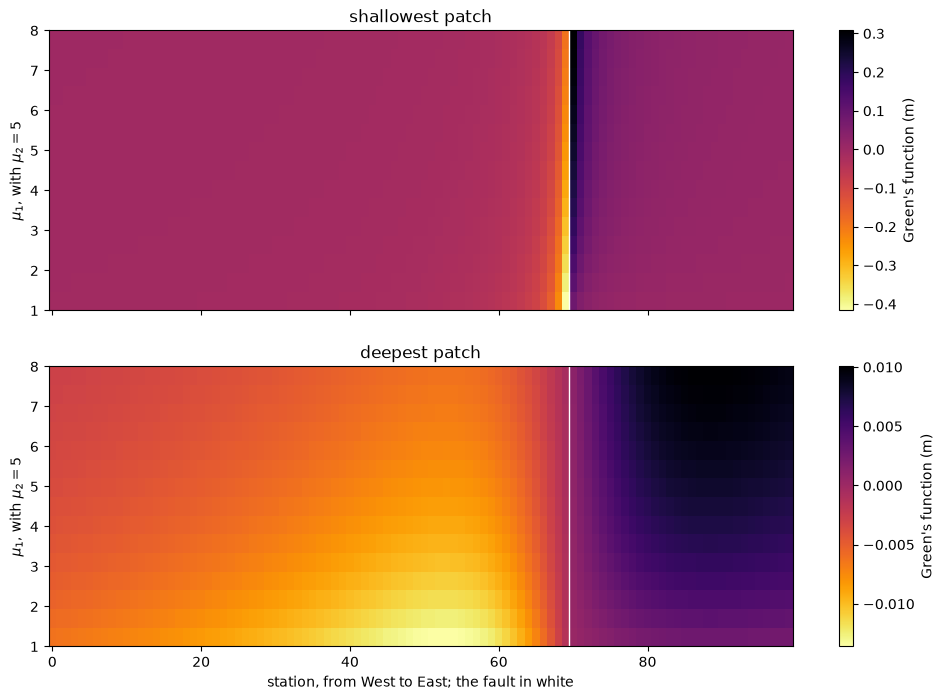

In [11]:
mus = np.linspace(1.0, 8.0, 15)
gfs = np.array([greens(x, width, patches, m, mu2) for m in mus])
fig, axes = plt.subplots(2, 1, figsize=(12, 8), sharex=True)
for ax, k, title in [(axes[0], 0, 'shallowest patch'), (axes[1], -1, 'deepest patch')]:
    im = ax.imshow(gfs[:, :, k], aspect='auto', cmap='inferno_r', origin='lower',
                   extent=[-0.5, len(x) - 0.5, mus[0], mus[-1]])
    ax.axvline(69.5, color='w', lw=1)
    fig.colorbar(im, ax=ax, label="Green's function (m)")
    ax.set_ylabel(r'$\mu_1$, with $\mu_2 = 5$'); ax.set_title(title)
axes[-1].set_xlabel('station, from West to East; the fault in white')
plt.show()

## 4. The prediction covariance $\mathbf{C}_\mathrm{p}$

### 4.1 The sensitivity kernels

$\mathbf{C}_\mathrm{p}$ follows from the sensitivity of the Green's functions to the uncertain parameters of the forward model, here the two shear moduli. A shear modulus is a scale parameter, so the kernels are the derivatives with respect to its logarithm (e.g., Tarantola, 2005):

$$
\mathbf{K}_\mu = \frac{\partial \mathbf{G}}{\partial \ln \mu} = \mu \, \frac{\partial \mathbf{G}}{\partial \mu}
$$

On the West side, $x_j < 0$,

$$
\mathbf{K}_{\mu_1}(x_j, f_i) = -\frac{2}{\pi} \, \frac{\mu_1 \mu_2}{(\mu_1 + \mu_2)^2} \left[ \tan^{-1} \left( \frac{d_{i+1}}{x_j} \right) - \tan^{-1} \left( \frac{d_i}{x_j} \right) \right], \qquad \mathbf{K}_{\mu_2} = -\mathbf{K}_{\mu_1}
$$

and the signs are the reverse on the East side. The two kernels cancel: scaling both shear moduli by the same factor doesn't change the Green's functions.

In [12]:
def kernels(x, width, patches, mu1, mu2):
    # the kernels dG/dln(mu1) and dG/dln(mu2), (2, stations, patches)
    d = np.linspace(0, width, patches + 1)
    c = 2 / np.pi * mu1 * mu2 / (mu1 + mu2) ** 2
    sign = np.where(x < 0, -1.0, 1.0)
    K1 = sign[:, None] * c * (np.arctan(d[None, 1:] / x[:, None]) - np.arctan(d[None, :-1] / x[:, None]))
    return np.array([K1, -K1])

K = kernels(x, width, patches, mu1, mu2)

A check against finite differences of the heterogeneous Green's functions:

In [13]:
h = 1e-6
dG1 = (greens(x, width, patches, mu1 * np.exp(h), mu2) - G_het) / h
dG2 = (greens(x, width, patches, mu1, mu2 * np.exp(h)) - G_het) / h
print(f"largest difference: mu1 kernel {np.abs(dG1 - K[0]).max():.1e}, mu2 kernel {np.abs(dG2 - K[1]).max():.1e}")

largest difference: mu1 kernel 2.2e-08, mu2 kernel 2.2e-08


### 4.2 The uncertainty of the shear moduli and the initial model

$\mathbf{C}_\mu$, the covariance of the logarithms of the shear moduli: independent, each with a variance of 0.1, a standard deviation of about 30%. And an initial slip model to compute $\mathbf{C}_\mathrm{p}$ from, before the samples firm up: a uniform slip of 5 m, half the true one.

In [14]:
Cmu = np.diag([0.1, 0.1])
initial = np.full(patches, s / 2)

### 4.3 $\mathbf{C}_\mathrm{p}$

For a slip model $\boldsymbol\theta$, the predictions change with the shear moduli as $\mathbf{K}_\mathrm{p} = [\mathbf{K}_{\mu_1} \boldsymbol\theta, \mathbf{K}_{\mu_2} \boldsymbol\theta]$, and

$$
\mathbf{C}_\mathrm{p} = \mathbf{K}_\mathrm{p} \, \mathbf{C}_\mu \, \mathbf{K}_\mathrm{p}^T
$$

AlTar adds it to $\mathbf{C}_\mathrm{d}$, for the misfit covariance $\mathbf{C}_\chi = \mathbf{C}_\mathrm{d} + \mathbf{C}_\mathrm{p}$. Computed here from the initial model, it can be given to AlTar as it is, a fixed $\mathbf{C}_\mathrm{p}$; or AlTar computes it again at each $\beta$ step, from the mean of the samples, given the kernels, $\mathbf{C}_\mu$ and the initial model. The kernels here are those of the component along strike; the other two components have no $\mathbf{C}_\mathrm{p}$.

In [15]:
Kp = (K @ initial).T            # (stations, 2)
Cp_x3 = Kp @ Cmu @ Kp.T
Cp = np.zeros((len(u), len(u)))
Cp[len(x):2 * len(x), len(x):2 * len(x)] = Cp_x3
print(f"the standard deviation of the predictions from C_p: up to {100 * np.sqrt(np.diag(Cp_x3)).max():.1f} cm, "
      f"against {100 * sigma_d:.1f} cm for the data")

the standard deviation of the predictions from C_p: up to 44.2 cm, against 13.8 cm for the data


## 5. The input files for AlTar

The files go to `test1`, with the names the static model `altar.models.seismic.static` looks for by default: the data and $\mathbf{C}_\mathrm{d}$, the homogeneous Green's functions, for the slip along strike only, (observations, patches), and for $\mathbf{C}_\mathrm{p}$, either the matrix itself, or the kernels, one per shear modulus, of the shape of the Green's functions, with $\mathbf{C}_\mu$ and the initial model.

In [16]:
os.makedirs(name, exist_ok=True)
zeros = np.zeros_like(G_hom)
files = {
    'static.data.h5': u,
    'static.Cd.h5': Cd,
    'static.gf.h5': np.concatenate((zeros, G_hom, zeros)),
    'static.Cp.h5': Cp,
    'static.Cmu.h5': Cmu,
    'static.initialModel.h5': initial,
}
for filename, values in files.items():
    with h5py.File(os.path.join(name, filename), 'w') as h5:
        h5[filename.removesuffix('.h5')] = values
with h5py.File(os.path.join(name, 'static.kernel.h5'), 'w') as h5:
    for i, k in enumerate(K):
        h5[f'K{i}'] = np.concatenate((zeros, k, zeros))
for filename in sorted(os.listdir(name)):
    with h5py.File(os.path.join(name, filename)) as h5:
        print(f"{filename}: " + ', '.join(f"{key} {h5[key].shape}" for key in h5))

static.Cd.h5: static.Cd (300, 300)
static.Cmu.h5: static.Cmu (2, 2)
static.Cp.h5: static.Cp (300, 300)
static.data.h5: static.data (300,)
static.gf.h5: static.gf (300, 20)
static.initialModel.h5: static.initialModel (20,)
static.kernel.h5: K0 (300, 20), K1 (300, 20)


The settings of the configuration files: the number of patches and of observations, and, to draw the initial samples from the seismic moment, the area of the patches and the moment magnitude of the true slip, for a shear modulus of 30 GPa:

In [17]:
area = (width / patches) * length / 1e6   # km^2
M0 = 30e9 * patches * area * 1e6 * s      # N m
print(f"patches = {patches}, observations = {len(u)}, patch area = {area:g} km^2, Mw = {(np.log10(M0) - 9.1) / 1.5:.2f}")

patches = 20, observations = 300, patch area = 250 km^2, Mw = 8.05


[Step 2](toymodel_step2.ipynb) configures and runs the inversions.